 # AI-Based Prescriptive Digital Twin for Green Hydrogen Production Optimization



 ## Notebook 04: Green Hydrogen Production Dataset

In [37]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path
import joblib
import shap #SHAP
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load Dataset

In [38]:
DATA_PATH = Path("D:/Digital Twin Graduation Project/SHAP + XAI/03_Dataset/01_Standardized/green_hydrogen_standardized.csv")
df = pd.read_csv(DATA_PATH)

In [39]:
df.sample(5)

,sample_id,timestamp,temperature_c,pressure_bar,voltage_v,current_density_a_cm2,water_flow_l_min,electrolyte_concentration_wt_pct,renewable_power_kw,efficiency_pct,hydrogen_production_kg_h
2991,2992,5/5/2026 15:00,77.88,20.95,1.676,0.791,1.161,23.12,446.84,72.41,5.982
2239,2240,4/4/2026 7:00,66.49,17.38,1.811,0.516,0.544,20.15,286.69,68.17,3.327
870,871,2/6/2026 6:00,74.74,11.75,2.027,0.301,4.557,23.48,230.13,62.15,2.827
558,559,1/24/2026 6:00,68.46,19.06,2.163,1.400,3.227,20.84,192.29,59.74,2.374
2378,2379,4/10/2026 2:00,50.35,7.28,1.836,1.573,4.574,31.05,298.20,70.98,4.165


# Data Preprocessing

## Initial verification

### Dataset Information

In [40]:
rows, cols = df.shape

print(f"Number of Samples : {rows}")
print(f"Number of Features: {cols}")

Number of Samples : 3000
Number of Features: 11


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   sample_id                         3000 non-null   int64  
 1   timestamp                         3000 non-null   object 
 2   temperature_c                     3000 non-null   float64
 3   pressure_bar                      3000 non-null   float64
 4   voltage_v                         3000 non-null   float64
 5   current_density_a_cm2             3000 non-null   float64
 6   water_flow_l_min                  3000 non-null   float64
 7   electrolyte_concentration_wt_pct  3000 non-null   float64
 8   renewable_power_kw                3000 non-null   float64
 9   efficiency_pct                    3000 non-null   float64
 10  hydrogen_production_kg_h          3000 non-null   float64
dtypes: float64(9), int64(1), object(1)
memory usage: 257.9+ KB


In [42]:
df.columns.tolist()

['sample_id',
 'timestamp',
 'temperature_c',
 'pressure_bar',
 'voltage_v',
 'current_density_a_cm2',
 'water_flow_l_min',
 'electrolyte_concentration_wt_pct',
 'renewable_power_kw',
 'efficiency_pct',
 'hydrogen_production_kg_h']

In [43]:
pd.DataFrame({
    "Column": df.columns,
    "Type": df.dtypes.values
})


,Column,Type
0,sample_id,int64
1,timestamp,object
2,temperature_c,float64
3,pressure_bar,float64
4,voltage_v,float64
5,current_density_a_cm2,float64
6,water_flow_l_min,float64
7,electrolyte_concentration_wt_pct,float64
8,renewable_power_kw,float64
9,efficiency_pct,float64


In [44]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sample_id,3000.0,NaN,NaN,NaN,1500.5,866.169729,1.0,750.75,1500.5,2250.25,3000.0
timestamp,3000,3000,1/1/2026 0:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature_c,3000.0,NaN,NaN,NaN,64.980603,11.605873,45.02,54.785,64.835,75.24,84.99
pressure_bar,3000.0,NaN,NaN,NaN,15.20924,8.304949,1.01,8.0475,15.115,22.2925,29.99
voltage_v,3000.0,NaN,NaN,NaN,1.901049,0.201435,1.55,1.72875,1.9035,2.071,2.25
current_density_a_cm2,3000.0,NaN,NaN,NaN,1.350051,0.662542,0.2,0.765,1.366,1.912,2.499
water_flow_l_min,3000.0,NaN,NaN,NaN,2.759397,1.285485,0.501,1.64425,2.775,3.86325,5.0
electrolyte_concentration_wt_pct,3000.0,NaN,NaN,NaN,27.56678,4.395161,20.0,23.7175,27.625,31.4,34.99
renewable_power_kw,3000.0,NaN,NaN,NaN,278.611803,131.363123,50.01,166.9425,282.85,392.535,499.97
efficiency_pct,3000.0,NaN,NaN,NaN,70.426527,6.877301,55.0,65.155,70.6,75.5325,88.0


## Missing Values

In [45]:
round(df.isnull().sum().sort_values(ascending=False)*100/len(df), 2)

sample_id                           0.0
timestamp                           0.0
temperature_c                       0.0
pressure_bar                        0.0
voltage_v                           0.0
current_density_a_cm2               0.0
water_flow_l_min                    0.0
electrolyte_concentration_wt_pct    0.0
renewable_power_kw                  0.0
efficiency_pct                      0.0
hydrogen_production_kg_h            0.0
dtype: float64

## Duplicate Rows

In [46]:
df.duplicated().sum()

np.int64(0)

## Outlier Detection

In [47]:
num_cols = df.select_dtypes(include="number").columns

In [48]:
for col in num_cols:

    fig = px.box(
        df,
        y=col,
        title=f"Outliers - {col}"
    )

    fig.show()


In [49]:
outliers_dict = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    outliers_dict[col] = len(outliers)

print(outliers_dict)

{'sample_id': 0, 'temperature_c': 0, 'pressure_bar': 0, 'voltage_v': 0, 'current_density_a_cm2': 0, 'water_flow_l_min': 0, 'electrolyte_concentration_wt_pct': 0, 'renewable_power_kw': 0, 'efficiency_pct': 0, 'hydrogen_production_kg_h': 0}


## Target Investigation

In [50]:
TARGET = "hydrogen_production_kg_h"

In [51]:
px.histogram(
    df,
    x=TARGET,
    color=TARGET,
    title="Hydrogen Production Distribution"
)


# Data Analysis and Visualization

## Feature Categories

| Category             | Features                                                |
| -------------------- | ------------------------------------------------------- |
| Operating Conditions | Temperature_C, Pressure_bar                             |
| Electrical           | Voltage_V, Current_Density_A_cm2                        |
| Water / Electrolyte  | Water_Flow_Rate_L_min, Electrolyte_Concentration_wt_pct |
| Energy               | Renewable_Power_kW                                      |
| Process Performance  | Efficiency_pct                                          |
| Target               | Hydrogen_Production_kg_h                                |



## Numerical Feature Distributions

In [52]:
for col in num_cols.drop("sample_id"):
    fig = px.histogram(df, x=col, title=f"Distribution of {col}")
    fig.show()

## Correlation Matrix

In [53]:
corr = df.corr(numeric_only=True)
corr

,sample_id,temperature_c,pressure_bar,voltage_v,current_density_a_cm2,water_flow_l_min,electrolyte_concentration_wt_pct,renewable_power_kw,efficiency_pct,hydrogen_production_kg_h
sample_id,1.000000,-0.001943,-0.005339,0.018054,-0.009273,0.038472,0.010417,0.026563,-0.000865,0.024622
temperature_c,-0.001943,1.000000,0.028991,-0.025873,-0.010291,0.022173,0.026210,0.023991,0.288847,0.169089
pressure_bar,-0.005339,0.028991,1.000000,0.012037,-0.020802,-0.019625,0.013189,-0.021818,-0.082508,-0.033945
voltage_v,0.018054,-0.025873,0.012037,1.000000,-0.002014,-0.000445,-0.023469,-0.002311,-0.835826,-0.212629
current_density_a_cm2,-0.009273,-0.010291,-0.020802,-0.002014,1.000000,-0.022546,-0.014252,-0.018763,0.207502,0.046753
water_flow_l_min,0.038472,0.022173,-0.019625,-0.000445,-0.022546,1.000000,0.010931,0.001870,0.006522,0.061464
electrolyte_concentration_wt_pct,0.010417,0.026210,0.013189,-0.023469,-0.014252,0.010931,1.000000,-0.002717,0.363453,0.071729
renewable_power_kw,0.026563,0.023991,-0.021818,-0.002311,-0.018763,0.001870,-0.002717,1.000000,0.005546,0.948255
efficiency_pct,-0.000865,0.288847,-0.082508,-0.835826,0.207502,0.006522,0.363453,0.005546,1.000000,0.268331
hydrogen_production_kg_h,0.024622,0.169089,-0.033945,-0.212629,0.046753,0.061464,0.071729,0.948255,0.268331,1.000000


In [54]:
corr[TARGET].sort_values(ascending=False)

hydrogen_production_kg_h            1.000000
renewable_power_kw                  0.948255
efficiency_pct                      0.268331
temperature_c                       0.169089
electrolyte_concentration_wt_pct    0.071729
water_flow_l_min                    0.061464
current_density_a_cm2               0.046753
sample_id                           0.024622
pressure_bar                       -0.033945
voltage_v                          -0.212629
Name: hydrogen_production_kg_h, dtype: float64

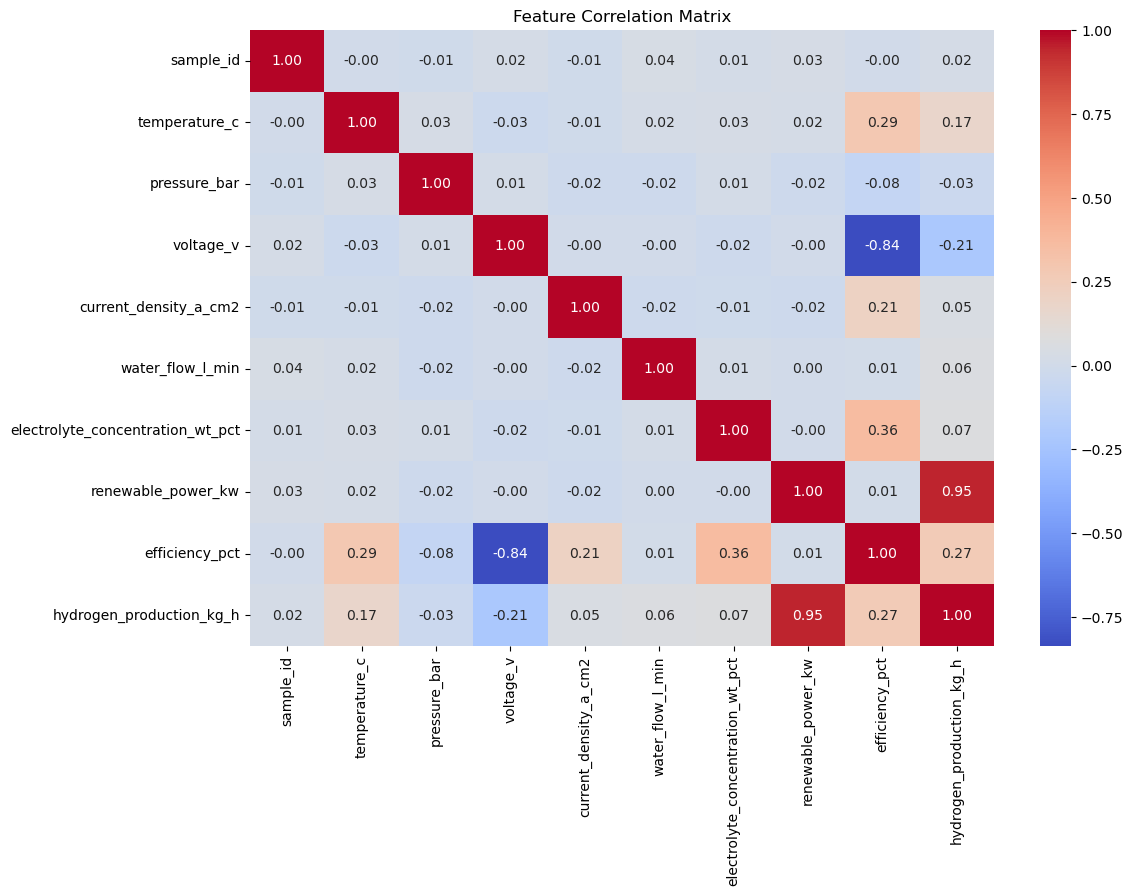

In [55]:
plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.show()

# Feature Selection

In [56]:
r=['hydrogen_production_kg_h','timestamp','sample_id',"efficiency_pct"]
X = df.drop(columns=r)
y = df['hydrogen_production_kg_h']
print(X.shape)
X.head()

(3000, 7)


,temperature_c,pressure_bar,voltage_v,current_density_a_cm2,water_flow_l_min,electrolyte_concentration_wt_pct,renewable_power_kw
0,75.96,25.05,1.869,2.209,2.831,25.21,111.52
1,62.56,18.23,1.633,0.766,2.091,21.54,409.62
2,79.34,8.10,1.948,1.325,0.838,24.53,494.68
3,72.89,22.62,1.660,0.268,4.959,32.10,212.18
4,48.77,3.45,1.593,0.220,1.286,27.40,439.41


# Train-Test Split

In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)
print(f"Training Samples : {len(X_train)}")
print(f"Testing Samples  : {len(X_test)}")

Training Samples : 2400
Testing Samples  : 600


# Feature Scaling

In [ ]:
num=X_train.select_dtypes(include=np.number).columns
scaler=StandardScaler()
X_train_scaled=X_train.copy()
X_test_scaled=X_test.copy()
X_train_scaled[num]=scaler.fit_transform(X_train[num])
X_test_scaled[num]=scaler.transform(X_test[num])
X_train_scaled.head()

,temperature_c,pressure_bar,voltage_v,current_density_a_cm2,water_flow_l_min,electrolyte_concentration_wt_pct,renewable_power_kw
642,-1.559519,1.146849,-1.035539,1.378132,-0.614979,-0.543474,0.677337
700,-0.898254,1.383983,-0.936251,-1.506120,0.129070,1.378580,0.168125
226,-1.642930,0.660483,-0.062514,1.734697,-1.704951,-0.652270,-1.563746
1697,1.007293,-0.036400,1.133909,0.370381,-0.533951,-1.053453,-1.723714
1010,0.542085,-0.790146,-1.492265,0.788892,-0.162317,-0.518542,-1.421408


In [59]:
print("Training Dataset Shape :", X_train_scaled.shape)
print("Testing Dataset Shape  :", X_test_scaled.shape)

print("Remaining Missing Values:")
print(X_train_scaled.isnull().sum().sum())

Training Dataset Shape : (2400, 7)
Testing Dataset Shape  : (600, 7)
Remaining Missing Values:
0


## Correlation Analysis

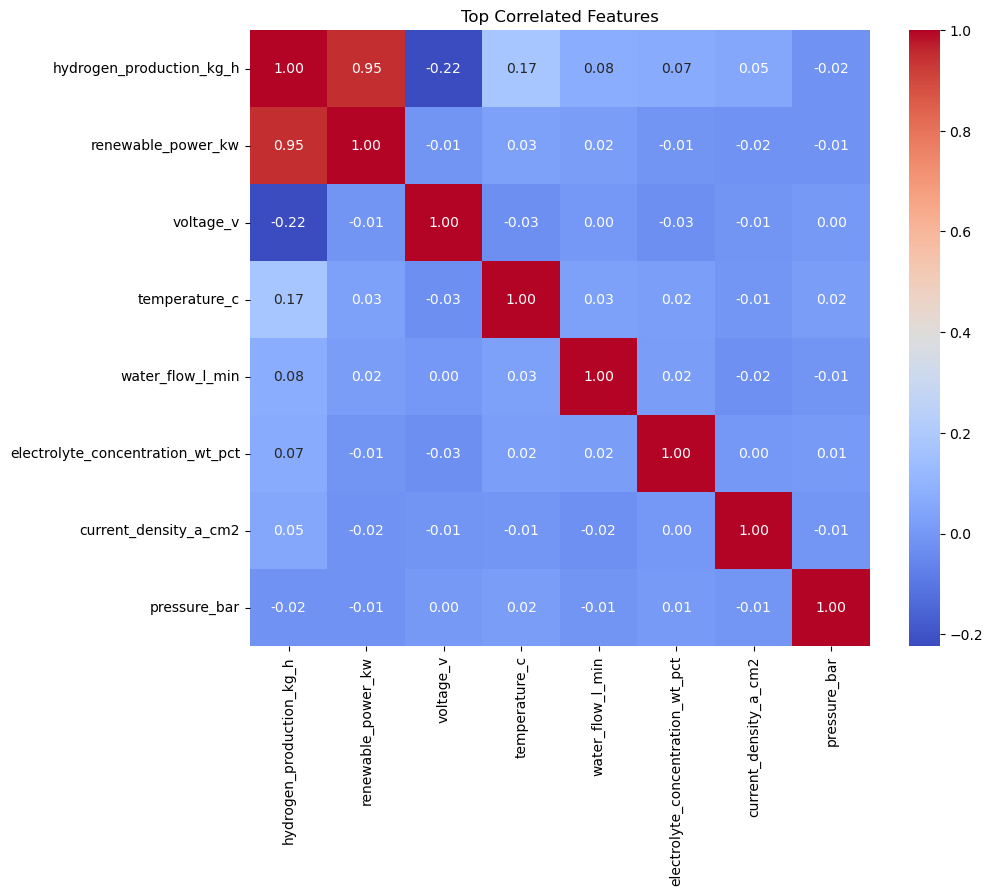

In [60]:
tmp=X_train_scaled.copy()
tmp['hydrogen_production_kg_h']=y_train.values
corr=tmp.corr(numeric_only=True)
top=corr['hydrogen_production_kg_h'].abs().sort_values(ascending=False).head(12).index
plt.figure(figsize=(10,8))
sns.heatmap(corr.loc[top,top],annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Top Correlated Features')
plt.show()

## Random Forest Feature Importance

In [61]:
rf = DecisionTreeRegressor(
    random_state=42
)

rf.fit(X_train_scaled, y_train)

importance = pd.Series(
    rf.feature_importances_,
    index=X_train_scaled.columns
).sort_values(ascending=False)

importance


renewable_power_kw                  0.901537
voltage_v                           0.055287
temperature_c                       0.023714
current_density_a_cm2               0.006438
electrolyte_concentration_wt_pct    0.005676
water_flow_l_min                    0.005299
pressure_bar                        0.002049
dtype: float64

In [62]:
px.bar(
    importance,
    title="Random Forest Feature Importance"
)


# Final Feature Selection

In [63]:
selected=importance.head(10).index.tolist()
X_train_final=X_train_scaled[selected]
X_test_final=X_test_scaled[selected]
print(selected)

['renewable_power_kw', 'voltage_v', 'temperature_c', 'current_density_a_cm2', 'electrolyte_concentration_wt_pct', 'water_flow_l_min', 'pressure_bar']


# Build Machine Learning Models

In [64]:
models = {

    "Linear Regression":
        LinearRegression(),

    "Decision Tree":
        DecisionTreeRegressor(
            random_state=42
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=300,
            random_state=42
        ),

    "XGBoost":
        XGBRegressor(
            random_state=42,
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6
        ),

    "LightGBM":
        LGBMRegressor(
            random_state=42,
            n_estimators=300,
            learning_rate=0.05
        ),

    "CatBoost":
        CatBoostRegressor(
            random_state=42,
            verbose=False
        )

}


 ## Train Models & Evaluate Performance

In [65]:
results = []

trained_models = {}

for name, model in models.items():

    model.fit(X_train_final, y_train)

    prediction = model.predict(X_test_final)

    mae = mean_absolute_error(
        y_test,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            prediction
        )
    )

    r2 = r2_score(
        y_test,
        prediction
    )

    results.append({

        "Model": name,

        "MAE": mae,

        "RMSE": rmse,

        "R2 Score": r2

    })

    trained_models[name] = model

results = pd.DataFrame(results)

results = results.sort_values(
    by="R2 Score",
    ascending=False
)

results


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000225 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1785
[LightGBM] [Info] Number of data points in the train set: 2400, number of used features: 7
[LightGBM] [Info] Start training from score 3.624732


,Model,MAE,RMSE,R2 Score
5,CatBoost,0.138287,0.172917,0.990473
4,LightGBM,0.153848,0.191056,0.988369
3,XGBoost,0.159439,0.201446,0.987070
2,Random Forest,0.180764,0.232753,0.982738
0,Linear Regression,0.222106,0.284635,0.974185
1,Decision Tree,0.277548,0.364991,0.957552


## Model Comparison Results

In [66]:
px.bar(

    results,

    x="Model",

    y="R2 Score",

    color="Model",

    title="Model Comparison (R² Score)"

)


In [67]:
px.bar(

    results,

    x="Model",

    y="RMSE",

    color="Model",

    title="RMSE Comparison"

)


In [68]:
px.bar(

    results,

    x="Model",

    y="MAE",

    color="Model",

    title="MAE Comparison"

)


 ## Select Best Model

In [69]:
best_model_name = results.iloc[0]["Model"]

print("Best Model :", best_model_name)

best_model = trained_models[best_model_name]


Best Model : CatBoost


## Best Model Validation

In [70]:
train_prediction = best_model.predict(X_train_final)

test_prediction = best_model.predict(X_test_final)

train_r2 = r2_score(
    y_train,
    train_prediction
)

test_r2 = r2_score(
    y_test,
    test_prediction
)

print(f"Best Model : {best_model_name}")
print(f"Train R² : {train_r2:.4f}")
print(f"Test  R² : {test_r2:.4f}")

Best Model : CatBoost
Train R² : 0.9975
Test  R² : 0.9905


### Cross Validation

In [71]:
cv_scores = cross_val_score(

    best_model,

    X_train_final,

    y_train,

    cv=5,

    scoring="r2"

)

print("Cross Validation Scores")

print(cv_scores)

print()

print(f"Average CV R² : {cv_scores.mean():.4f}")
print(f"Std CV        : {cv_scores.std():.4f}")

Cross Validation Scores
[0.99125584 0.99070621 0.98999303 0.99078864 0.99071188]

Average CV R² : 0.9907
Std CV        : 0.0004


### Prediction Visualization

In [72]:
prediction = best_model.predict(X_test_final)

comparison = pd.DataFrame({

    "Actual": y_test,

    "Predicted": test_prediction

})

comparison.head()


,Actual,Predicted
1801,3.772,3.834434
1190,6.177,6.112909
1817,2.593,2.789856
251,1.817,1.843058
2505,4.872,4.945133


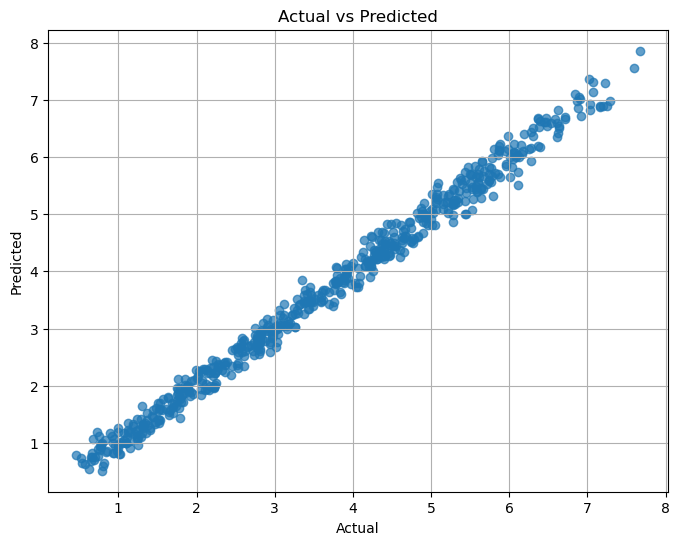

In [73]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    prediction,
    alpha=0.7
)

plt.xlabel("Actual")

plt.ylabel("Predicted")

plt.title("Actual vs Predicted")

plt.grid(True)

plt.show()


### Residual Analysis

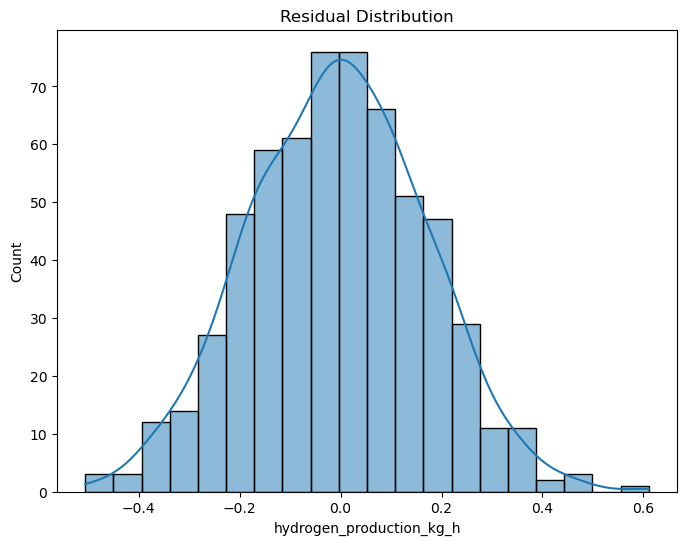

In [74]:
residuals = y_test - test_prediction

plt.figure(figsize=(8,6))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Residual Distribution")

plt.show()


### Validation Summary

In [77]:
gap = train_r2 - test_r2

print(f"Train-Test Gap : {gap:.4f}")

if gap < 0.05:
    print("Model Generalization : Excellent")

elif gap < 0.10:
    print("Model Generalization : Good")

else:
    print("Potential Overfitting Detected")

Train-Test Gap : 0.0070
Model Generalization : Excellent


 ## Save Best Model

In [78]:
OUTPUT = Path("00_Trained_Model/Green_Hydrogen")

OUTPUT.mkdir(exist_ok=True)

joblib.dump(

    best_model,

    OUTPUT / "best_Green_Hydrogen_model.pkl"

)

print("Best model saved successfully.")
print( OUTPUT / "best_Green_Hydrogen_model.pkl")

joblib.dump(
    scaler,
    OUTPUT / "Green_Hydrogen_scaler.pkl"
)

pd.DataFrame({"Feature": X_test_scaled[selected].columns}).to_csv(
    OUTPUT / "Green_Hydrogen_selected_features.csv",
    index=False
)

print("Green Hydrogen scaler and selected features saved successfully.")

FileNotFoundError: [WinError 3] The system cannot find the path specified: '00_Trained_Model\\Green_Hydrogen'

# Background Sample For SHAP

In [80]:
background = X_train_scaled.sample(
    n=min(100, len(X_train_scaled)),
    random_state=42
)

print("Background shape:", background.shape)

Background shape: (100, 7)


# Load Best Fit Model

In [82]:
dt_model = models["Decision Tree"]

print(dt_model)

DecisionTreeRegressor(random_state=42)


# Explanation Sample

In [83]:
X_explain = X_test_scaled.iloc[:500]

print("Explanation shape:", X_explain.shape)

Explanation shape: (500, 7)


# Decision Tree TreeExplainer

In [84]:
dt_explainer = shap.TreeExplainer(
    dt_model,
    data=background
)

# Calculate SHAP Values

In [85]:
dt_shap_values = dt_explainer(X_explain)

print("SHAP shape:", dt_shap_values.values.shape)

SHAP shape: (500, 7)


# Global Feature Importance

In [86]:
dt_importance = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean_Absolute_SHAP": np.abs(
        dt_shap_values.values
    ).mean(axis=0)
})

dt_importance = dt_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

dt_importance

,Feature,Mean_Absolute_SHAP
6,renewable_power_kw,1.529854
2,voltage_v,0.327876
0,temperature_c,0.193579
3,current_density_a_cm2,0.067415
5,electrolyte_concentration_wt_pct,0.059308
4,water_flow_l_min,0.058211
1,pressure_bar,0.016714


# SHAP Bar Plot

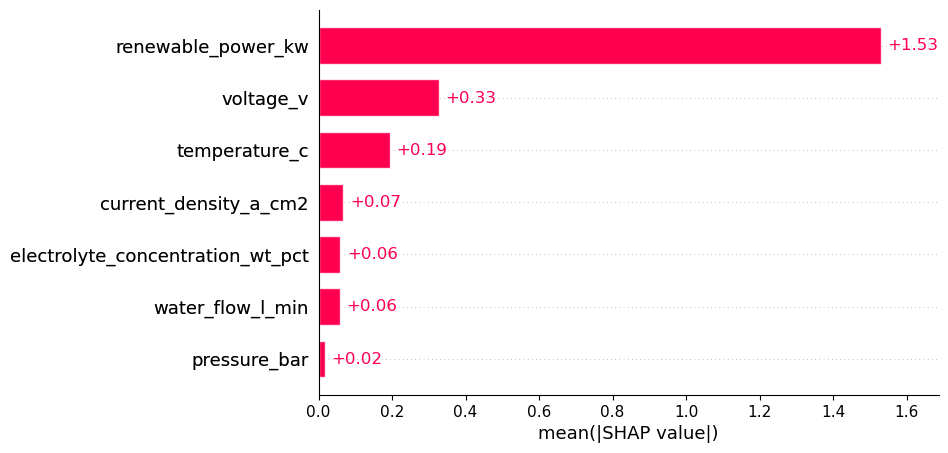

In [87]:
shap.plots.bar(dt_shap_values)

# SHAP Beeswarm

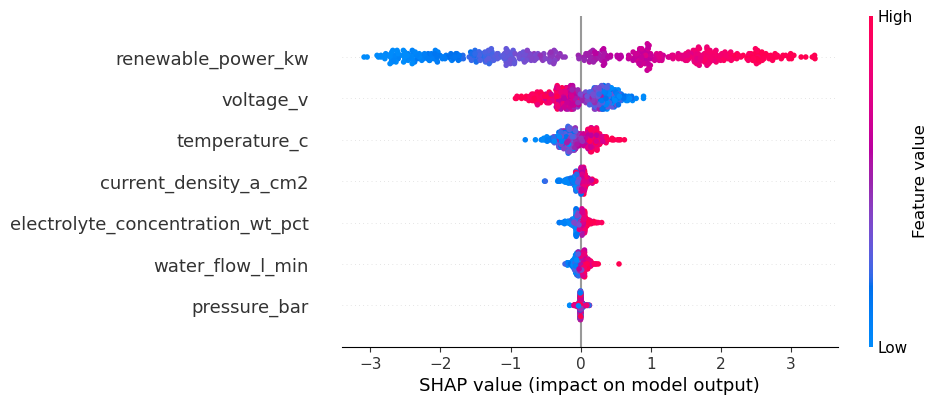

In [88]:
shap.plots.beeswarm(dt_shap_values)

# Dependence Plot

Most important feature: renewable_power_kw


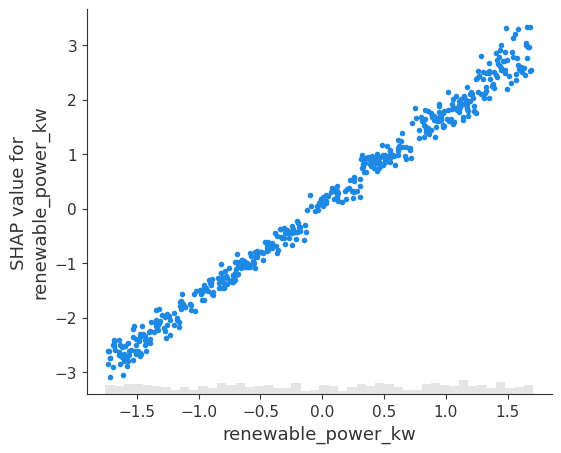

In [90]:
top_feature = dt_importance.iloc[0]["Feature"]

print("Most important feature:", top_feature)
shap.plots.scatter(
    dt_shap_values[:, top_feature]
)

# Local Explanation

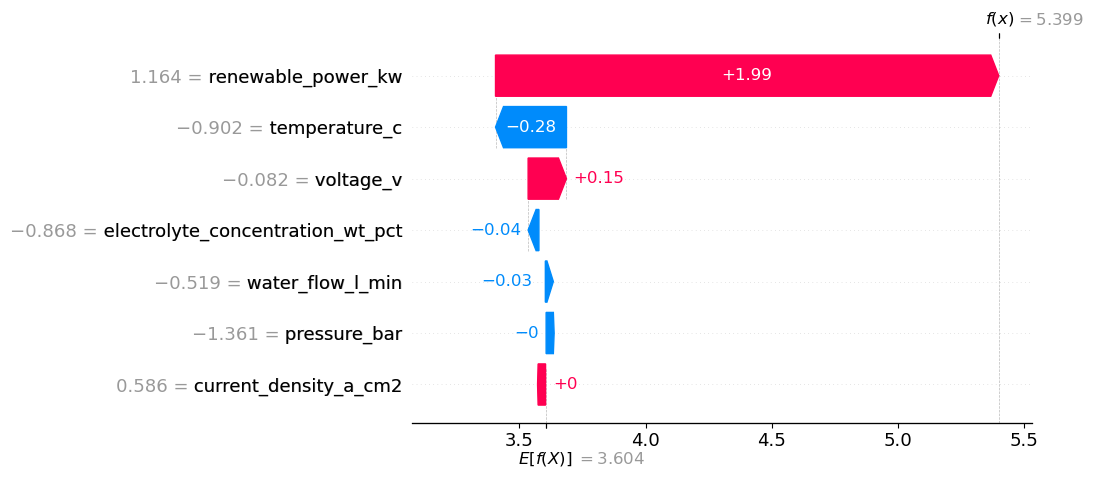

In [91]:
sample_index = 50 
shap.plots.waterfall(
    dt_shap_values[sample_index]
)

# Local Contribution Table

In [92]:
local_table_dt = pd.DataFrame({
    "Feature": X_explain.columns,
    "Feature_Value": X_explain.iloc[sample_index].values,
    "SHAP_Value": dt_shap_values.values[sample_index]
})

local_table_dt["Absolute_SHAP"] = (
    local_table_dt["SHAP_Value"].abs()
)

local_table_dt["Effect"] = np.where(
    local_table_dt["SHAP_Value"] > 0,
    "Pushes output higher",
    "Pushes output lower"
)

local_table_dt = local_table_dt.sort_values(
    by="Absolute_SHAP",
    ascending=False
)

local_table_dt

,Feature,Feature_Value,SHAP_Value,Absolute_SHAP,Effect
6,renewable_power_kw,1.164340,1.993564,1.993564,Pushes output higher
0,temperature_c,-0.901693,-0.281065,0.281065,Pushes output lower
2,voltage_v,-0.082372,0.151888,0.151888,Pushes output higher
5,electrolyte_concentration_wt_pct,-0.867594,-0.042791,0.042791,Pushes output lower
4,water_flow_l_min,-0.519148,-0.025452,0.025452,Pushes output lower
1,pressure_bar,-1.361203,-0.003092,0.003092,Pushes output lower
3,current_density_a_cm2,0.586436,0.002197,0.002197,Pushes output higher


# Positive / Negative Effects

In [93]:
positive_effects_dt = local_table_dt[
    local_table_dt["SHAP_Value"] > 0
]

negative_effects_dt = local_table_dt[
    local_table_dt["SHAP_Value"] < 0
]

print("Positive effects:")
display(positive_effects_dt)

print("\nNegative effects:")
display(negative_effects_dt)

Positive effects:


,Feature,Feature_Value,SHAP_Value,Absolute_SHAP,Effect
6,renewable_power_kw,1.164340,1.993564,1.993564,Pushes output higher
2,voltage_v,-0.082372,0.151888,0.151888,Pushes output higher
3,current_density_a_cm2,0.586436,0.002197,0.002197,Pushes output higher



Negative effects:


,Feature,Feature_Value,SHAP_Value,Absolute_SHAP,Effect
0,temperature_c,-0.901693,-0.281065,0.281065,Pushes output lower
5,electrolyte_concentration_wt_pct,-0.867594,-0.042791,0.042791,Pushes output lower
4,water_flow_l_min,-0.519148,-0.025452,0.025452,Pushes output lower
1,pressure_bar,-1.361203,-0.003092,0.003092,Pushes output lower


# Force Plot

In [94]:
shap.initjs()

shap.plots.force(
    dt_shap_values[sample_index]
)

# Save SHAP Values

In [95]:
dt_shap_df = pd.DataFrame(
    dt_shap_values.values,
    columns=X_explain.columns,
    index=X_explain.index
)

dt_shap_df.to_csv(
    "decision_tree_shap_values.csv"
)

# Save Global Importance

In [96]:
dt_importance.to_csv(
    "decision_tree_global_feature_importance.csv",
    index=False
)

# Save Local Contribution

In [99]:
local_table_dt.to_csv(
    "decision_tree_local_contribution.csv",
    index=False
)